In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("/content/archive.zip")

In [3]:
print(df.head())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


Step 2: Inspect the structure of the data
Why? Before analyzing data, you should understand its dimensions, column names, data types, and general structure.

In [9]:
# number in the row and columns
print(df.shape)
#  columns names
print(df.columns)
# data types
print(df.dtypes)

(1338, 7)
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [11]:
# Random sample of 5 rows
display(df.sample(5, random_state=42))

,age,sex,bmi,children,smoker,region,charges
764,45,female,25.175,2,no,northeast,9095.06825
887,36,female,30.020,0,no,northwest,5272.17580
890,64,female,26.885,0,yes,northwest,29330.98315
1293,46,male,25.745,3,no,northwest,9301.89355
259,19,male,31.920,0,yes,northwest,33750.29180


In [12]:
# check the missing value in each columns
print(df.isnull().sum())


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [13]:
print((df.isnull().mean() * 100).round(2))

age         0.0
sex         0.0
bmi         0.0
children    0.0
smoker      0.0
region      0.0
charges     0.0
dtype: float64


In [14]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [15]:
df.describe(include="object")

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


Step 6: Univariate Analysis — visualizing each variable individually.
Start by plotting histograms:

array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'bmi'}>],
       [<Axes: title={'center': 'children'}>,
        <Axes: title={'center': 'charges'}>]], dtype=object)

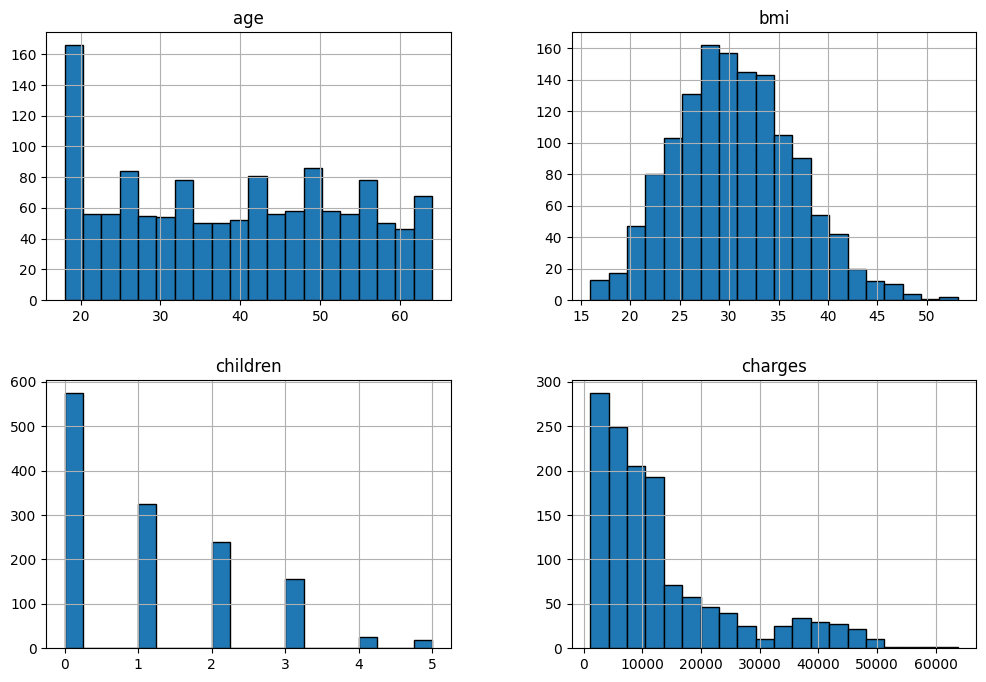

In [17]:
import matplotlib.pyplot as plt
df.hist(figsize=(12,8), bins = 20, edgecolor = "black")

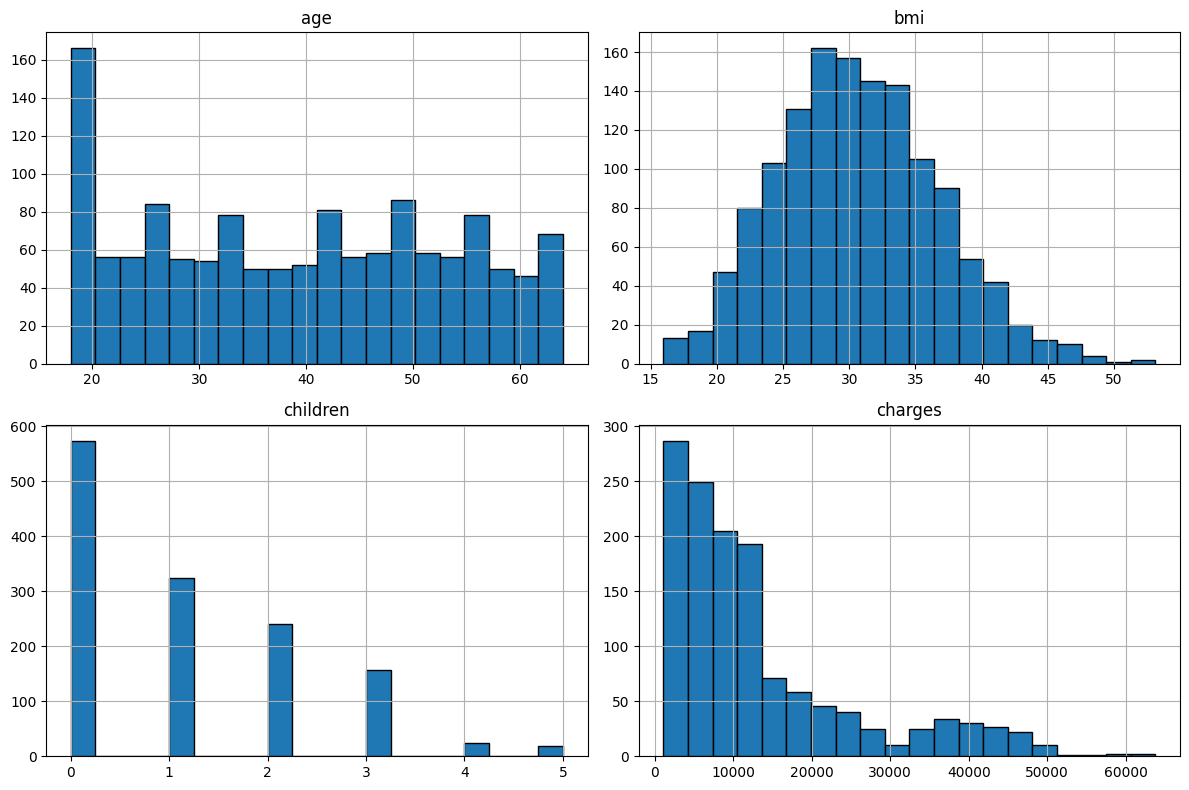

In [20]:
plt.tight_layout()

In [22]:
plt.show()

In [23]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [21]:
import seaborn as sns

numerical_cols = ["age", "bmi", "children", "charges"]

plt.figure(figsize=(12, 6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

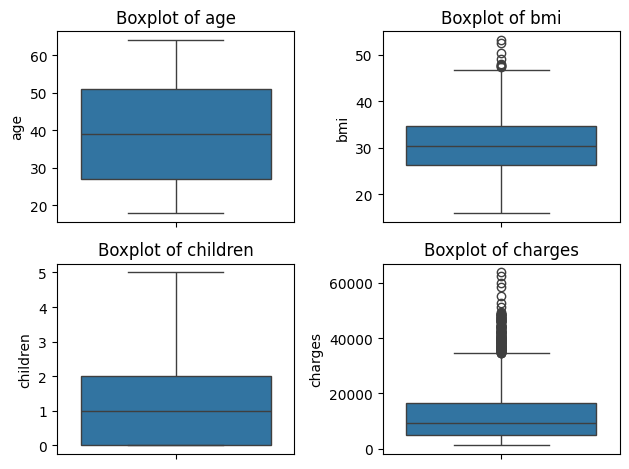

In [24]:
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [25]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


let's understand how many records belong to each category

In [26]:
categorical_cols = ["sex", "smoker", "region"]

for col in categorical_cols:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts())


Distribution of sex:
sex
male      676
female    662
Name: count, dtype: int64

Distribution of smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

Distribution of region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


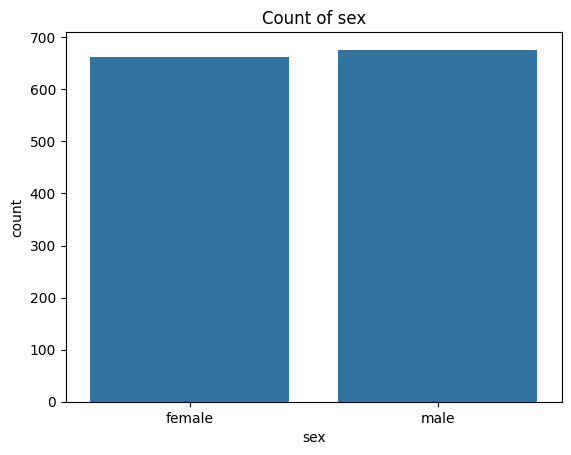

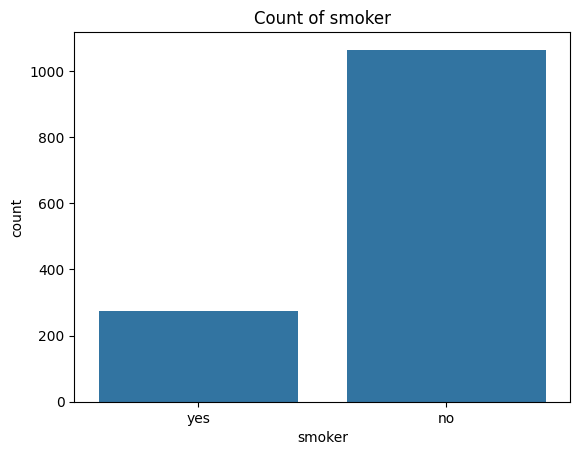

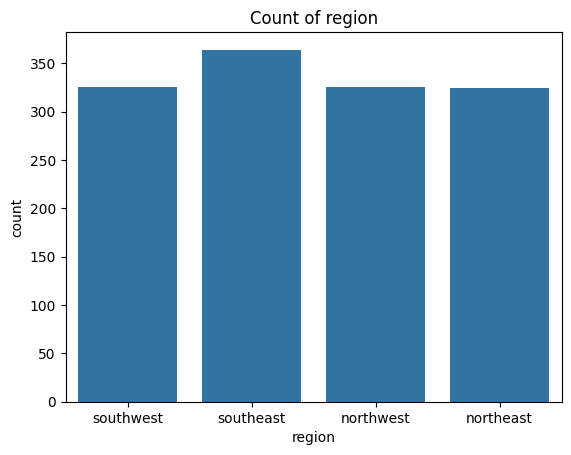

In [27]:
for col in categorical_cols:
    sns.countplot(data=df, x=col)
    plt.title(f"Count of {col}")
    plt.show()

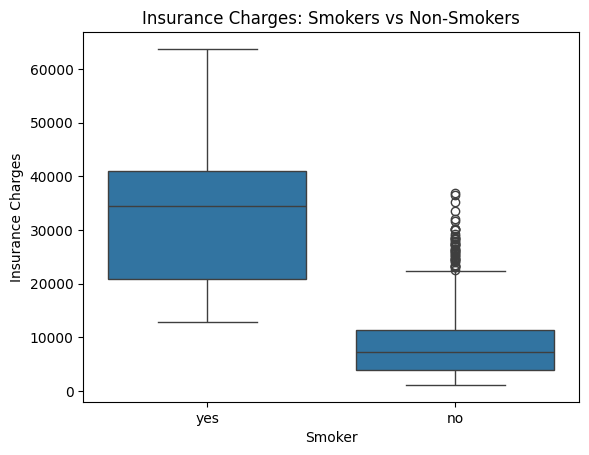

In [28]:
sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Insurance Charges: Smokers vs Non-Smokers")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")
plt.show()

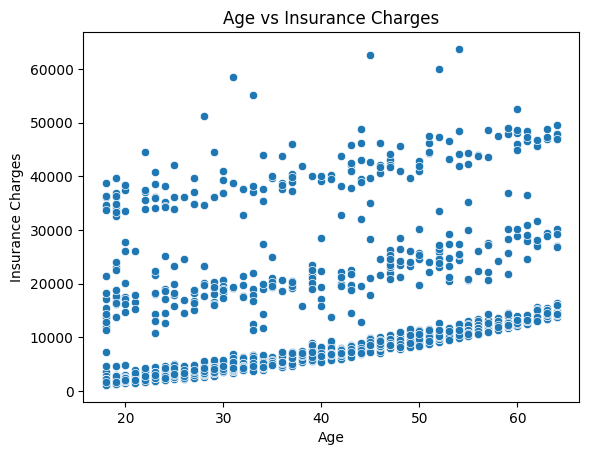

In [29]:
sns.scatterplot(data=df, x="age", y="charges")

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.show()

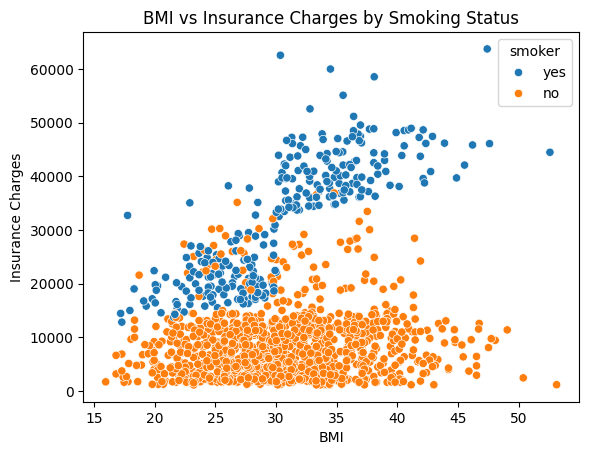

In [30]:
sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)

plt.title("BMI vs Insurance Charges by Smoking Status")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.show()

In [33]:
print(
    df.groupby("smoker")["charges"]
      .agg(["count", "mean", "median"])
      .round(2)
)

        count      mean    median
smoker                           
no       1064   8434.27   7345.41
yes       274  32050.23  34456.35


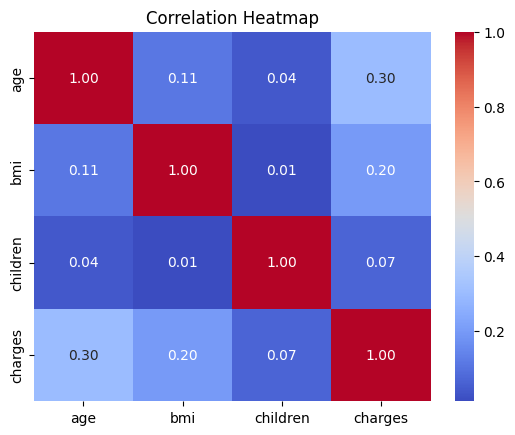

In [34]:
numerical_cols = ["age", "bmi", "children", "charges"]

corr = df[numerical_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [36]:
# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

display(df_encoded.head())

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [37]:
X = df_encoded.drop(columns=["charges"])
y = df_encoded["charges"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1338, 8)
Target shape: (1338,)


testing and training dataset


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1070
Testing records: 268


1. model linear regression


In [39]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [40]:
model.fit(X_train, y_train)

LinearRegression()

In [41]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656 10864.11316424   170.28084136 16903.45028662
  1092.43093614 11218.34318352]


In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE: 4181.19
MSE: 33596915.85
RMSE: 5796.28
R2 Score: 0.7836


In [43]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("MAE:", round(mean_absolute_error(y_test, rf_pred), 2))
print("MSE:", round(mean_squared_error(y_test, rf_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 2))
print("R2 Score:", round(r2_score(y_test, rf_pred), 4))

Random Forest Results
MAE: 2489.71
MSE: 19816410.23
RMSE: 4451.56
R2 Score: 0.8724


            Feature  Importance
4        smoker_yes    0.634213
1               bmi    0.203385
0               age    0.132413
2          children    0.014695
3          sex_male    0.004552
5  region_northwest    0.004146
6  region_southeast    0.003654
7  region_southwest    0.002941


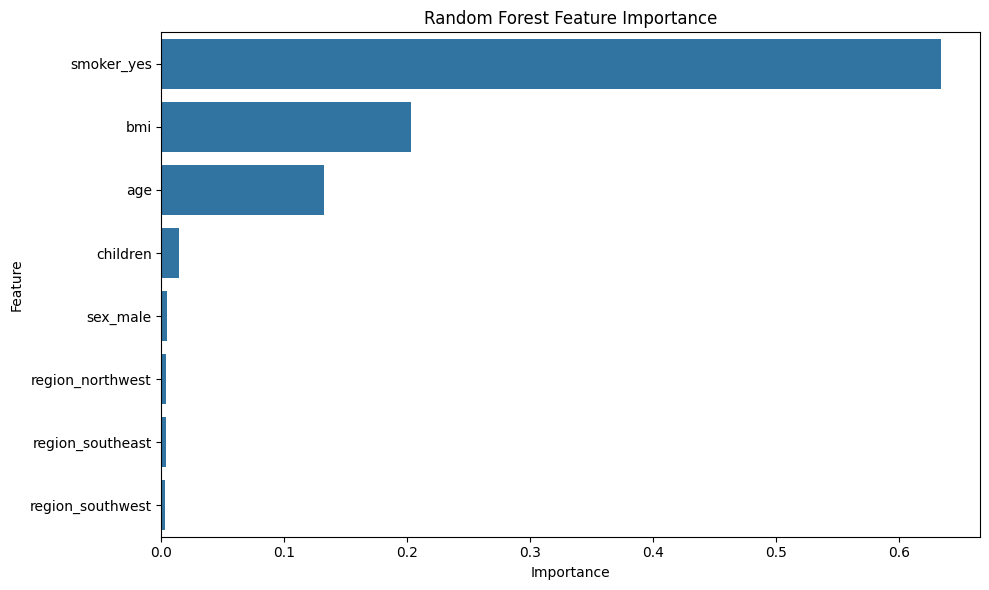

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

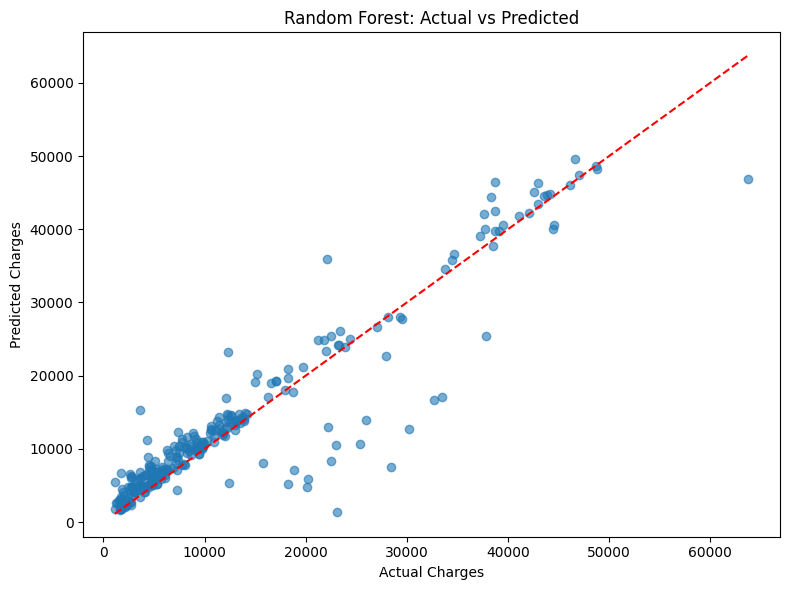

In [45]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.6)

low = min(y_test.min(), rf_pred.min())
high = max(y_test.max(), rf_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Random Forest: Actual vs Predicted")

plt.tight_layout()
plt.show()

In [47]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0]
}

rf = RandomForestRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=25,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("Best cross-validation MAE:")
print(round(-random_search.best_score_, 2))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 1.0, 'max_depth': 5}
Best cross-validation MAE:
2613.53


In [48]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

best_model = random_search.best_estimator_

tuned_pred = best_model.predict(X_test)

print("Tuned Random Forest Results")
print("MAE:", round(mean_absolute_error(y_test, tuned_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_pred)), 2))
print("R2 Score:", round(r2_score(y_test, tuned_pred), 4))

Tuned Random Forest Results
MAE: 2506.87
RMSE: 4359.19
R2 Score: 0.8776


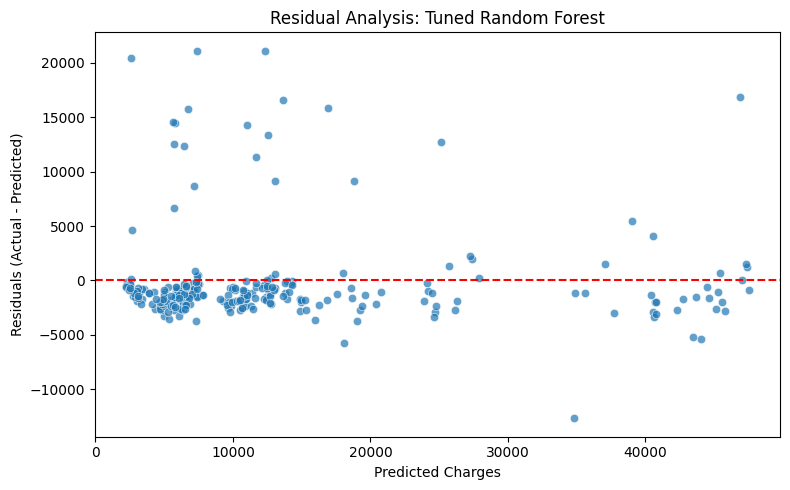

In [49]:
residuals = y_test - tuned_pred

# Actual minus predicted charges
plt.figure(figsize=(8, 5))
sns.scatterplot(x=tuned_pred, y=residuals, alpha=0.7)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis: Tuned Random Forest")
plt.tight_layout()
plt.show()

In [50]:
error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": tuned_pred
})

error_analysis["Absolute_Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

display(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

,Actual,Predicted,Absolute_Error
599,33471.97189,12342.529008,21129.442882
806,28476.73499,7353.327459,21123.407531
430,23082.95533,2583.735701,20499.219629
543,63770.42801,46872.286496,16898.141514
115,30259.99556,13625.252350,16634.743210
128,32734.18630,16910.103787,15824.082513
1039,22493.65964,6743.749391,15749.910249
306,20177.67113,5612.985709,14564.685421
291,20277.80751,5797.625752,14480.181758
925,25333.33284,11028.232112,14305.100728


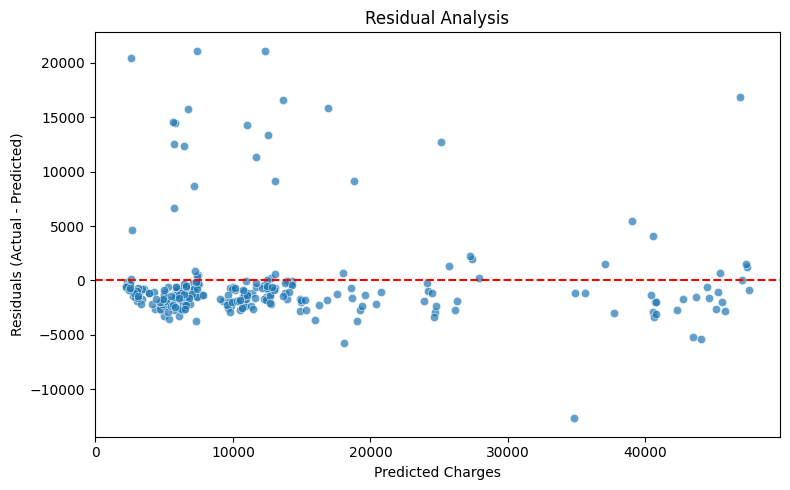

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals = y_test - tuned_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=tuned_pred,
    y=residuals,
    alpha=0.7
)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis")

plt.tight_layout()
plt.show()

In [52]:
# Reconstruct the test records from the original DataFrame
test_data = df.loc[X_test.index].copy()

test_data["Actual"] = y_test
test_data["Predicted"] = tuned_pred
test_data["Absolute_Error"] = (
    test_data["Actual"] - test_data["Predicted"]
).abs()

display(
    test_data.sort_values(
        "Absolute_Error",
        ascending=False
    )[[
        "age", "bmi", "smoker", "children",
        "region", "Actual", "Predicted", "Absolute_Error"
    ]].head(10)
)

,age,bmi,smoker,children,region,Actual,Predicted,Absolute_Error
599,52,37.525,no,2,northwest,33471.97189,12342.529008,21129.442882
806,40,41.420,no,1,northwest,28476.73499,7353.327459,21123.407531
430,19,33.100,no,0,southwest,23082.95533,2583.735701,20499.219629
543,54,47.410,yes,0,southeast,63770.42801,46872.286496,16898.141514
115,60,28.595,no,0,northeast,30259.99556,13625.252350,16634.743210
128,32,17.765,yes,2,northwest,32734.18630,16910.103787,15824.082513
1039,19,27.265,no,2,northwest,22493.65964,6743.749391,15749.910249
306,28,27.500,no,2,southwest,20177.67113,5612.985709,14564.685421
291,29,29.640,no,1,northeast,20277.80751,5797.625752,14480.181758
925,50,32.110,no,2,northeast,25333.33284,11028.232112,14305.100728


In [53]:
test_data["Error"] = test_data["Actual"] - test_data["Predicted"]

test_data.groupby("smoker").agg(
    Mean_Absolute_Error=("Absolute_Error", "mean"),
    Average_Error=("Error", "mean"),
    Number_of_People=("Actual", "count")
).round(2)

,Mean_Absolute_Error,Average_Error,Number_of_People
smoker,,,
no,2402.53,-260.34,214
yes,2920.37,-462.33,54


In [59]:
print(best_model if "best_model" in globals() else "best_model not found")
print(random_search.best_estimator_ if "random_search" in globals() else "random_search not found")

tuned_model = random_search.best_estimator_
print(tuned_model)

RandomForestRegressor(max_depth=5, min_samples_leaf=4, min_samples_split=10,
                      random_state=42)
RandomForestRegressor(max_depth=5, min_samples_leaf=4, min_samples_split=10,
                      random_state=42)
RandomForestRegressor(max_depth=5, min_samples_leaf=4, min_samples_split=10,
                      random_state=42)


            Feature  Importance
4        smoker_yes    0.684594
1               bmi    0.184746
0               age    0.120035
2          children    0.007751
6  region_southeast    0.000818
7  region_southwest    0.000761
5  region_northwest    0.000691
3          sex_male    0.000604


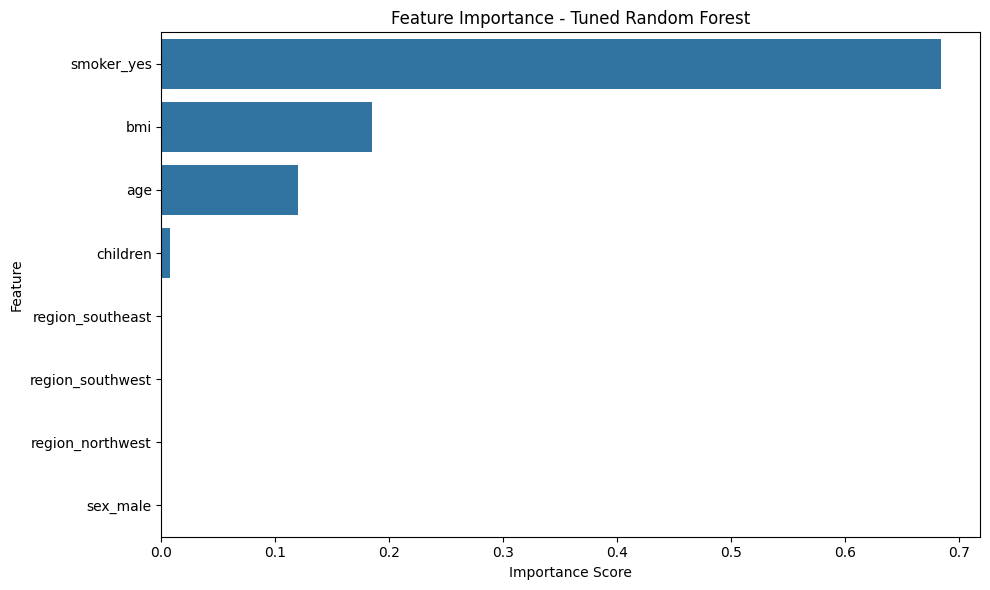

In [60]:


# Get feature importance from the trained tuned model
importance = tuned_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the results
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [63]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# 1. Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 2. Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)
rf_model.fit(X_train, y_train)

print("Linear Regression and Random Forest trained successfully!")

Linear Regression and Random Forest trained successfully!


In [64]:

# Generate predictions
linear_pred = linear_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
tuned_pred = tuned_model.predict(X_test)

# Evaluate models
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_pred),
    evaluate_model("Random Forest", y_test, rf_pred),
    evaluate_model("Tuned Random Forest", y_test, tuned_pred)
])

print(results.round(3))

                 Model       MAE      RMSE  R2 Score
0    Linear Regression  4181.194  5796.285     0.784
1        Random Forest  2489.713  4451.563     0.872
2  Tuned Random Forest  2506.871  4359.191     0.878


In [65]:
import joblib

# Save the tuned Random Forest model
joblib.dump(tuned_model, "insurance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [66]:
# Load the saved model
loaded_model = joblib.load("insurance_model.pkl")

# Make predictions using the loaded model
sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("First 5 predictions:")
print(sample_predictions)

First 5 predictions:
[ 9796.12481909  5856.76807143 27398.51044786 10168.19699811
 34875.82655543]
